<a href="https://colab.research.google.com/github/LeelaLahari/AML_risk_graph/blob/main/notebooks/india_climate_risk_score.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install earthengine-api geemap geopandas pandas scikit-learn matplotlib

In [ ]:
import os
from pathlib import Path
import ee

cred_path = Path.home() / '.config' / 'earthengine' / 'credentials'
if cred_path.exists():
    cred_path.unlink()
    print('Cleared cached credentials')

ee.Authenticate(force=True)
ee.Initialize(project='india-climate-risk-scorecard')

save_path="/content/drive/MyDrive/Projects_Resume/HDFC_Geospatial"

In [ ]:
import geemap

#ee.Initialize(project="india-climate-risk-scorecard")

districts = (ee.FeatureCollection("FAO/GAUL/2015/level2")
             .filter(ee.Filter.eq("ADM0_NAME", "India")))

chirps = ee.ImageCollection("UCSB-CHG/CHIRPS/DAILY").select("precipitation")

def heavy_days(year):
    year = ee.Number(year)
    start = ee.Date.fromYMD(year, 1, 1)
    daily = chirps.filterDate(start, start.advance(1, "year"))
    return (daily.map(lambda img: img.gte(64.5))
                 .sum().rename("heavy_days").set("year", year))

years = ee.List.sequence(2000, 2023)
mean_heavy = ee.ImageCollection(years.map(heavy_days)).mean()

stats = mean_heavy.reduceRegions(
    collection=districts,
    reducer=ee.Reducer.mean(),
    scale=5566)          # CHIRPS native ~0.05 degrees

gdf = geemap.ee_to_gdf(stats)
gdf[["ADM1_NAME", "ADM2_NAME", "mean"]].to_csv(f"{save_path}/heavy_rain_days.csv", index=False)

In [ ]:
import ee
import pandas as pd

# Initialize the Earth Engine API
#ee.Initialize()

# 1. Get the dataset
fc = ee.FeatureCollection("FAO/GAUL/2015/level2")

# 2. Get the exact row count (Size) server-side
total_rows = fc.size().getInfo()

# 3. Safely pull only the first 5 rows to look at the columns/attributes
first_5_features = fc.limit(5).getInfo()["features"]

# 4. Parse the properties into a Pandas DataFrame
data = [f["properties"] for f in first_5_features]
df_head = pd.DataFrame(data)

# 5. Determine total columns from the sample
total_cols = len(df_head.columns)

# Output results
print(f"Shape of the complete dataset: ({total_rows}, {total_cols})")
print("\nFirst 5 rows:")
print(df_head)


Shape of the complete dataset: (38258, 12)

First 5 rows:
   ADM0_CODE                    ADM0_NAME  ADM1_CODE ADM1_NAME  ADM2_CODE  \
0        257  United Republic of Tanzania      48357    Arusha     115068   
1        257  United Republic of Tanzania     115003    Iringa     115032   
2        257  United Republic of Tanzania     115003    Iringa     115069   
3        257  United Republic of Tanzania      48365   Manyara     115119   
4        257  United Republic of Tanzania      48373     Pwani     115056   

      ADM2_NAME DISP_AREA  EXP2_YEAR        STATUS  STR2_YEAR  Shape_Area  \
0        Karatu        NO       3000  Member State       1995    0.263517   
1  Iringa Rural        NO       3000  Member State       1995    1.538828   
2        Kilolo        NO       3000  Member State       1995    0.757753   
3         Mbulu        NO       3000  Member State       1995    0.309377   
4      Kisarawe        NO       3000  Member State       1995    0.411885   

   Shape_Leng  


In [ ]:
import ee, geemap, pandas as pd, numpy as np
ee.Initialize(project="india-climate-risk-scorecard")

districts = (ee.FeatureCollection("FAO/GAUL/2015/level2")
             .filter(ee.Filter.eq("ADM0_NAME", "India")))
chirps = ee.ImageCollection("UCSB-CHG/CHIRPS/DAILY").select("precipitation")
years = ee.List.sequence(2000, 2023)
KEYS = ["ADM2_CODE", "ADM1_NAME", "ADM2_NAME"]

def zonal(img, scale, tile=4):
    fc = img.reduceRegions(collection=districts, reducer=ee.Reducer.mean(),
                           scale=scale, tileScale=tile)
    return geemap.ee_to_gdf(fc)

## Flood Indicators

In [ ]:
# F2: Rx1day = annual maximum 1-day rainfall, averaged over years
def rx1day(y):
    s = ee.Date.fromYMD(ee.Number(y), 1, 1)
    return chirps.filterDate(s, s.advance(1, "year")).max().rename("rx1day")
rx1 = ee.ImageCollection(years.map(rx1day)).mean()

# F3: JRC permanent/seasonal surface water occurrence (0-100 %)
water = (ee.Image("JRC/GSW1_4/GlobalSurfaceWater")
         .select("occurrence").unmask(0).rename("water_occ"))

# F4: low-lying and flat terrain (elevation and slope)
dem = ee.Image("NASA/NASADEM_HGT/001").select("elevation")
terrain = dem.addBands(ee.Terrain.slope(dem).rename("slope"))

flood = zonal(rx1, 5566)[KEYS + ["mean"]].rename(columns={"mean": "rx1day"})
flood = flood.merge(zonal(water, 1000)[["ADM2_CODE", "mean"]]
                    .rename(columns={"mean": "water_occ"}), on="ADM2_CODE")
flood = flood.merge(zonal(terrain, 1000)[["ADM2_CODE", "elevation", "slope"]],
                    on="ADM2_CODE")
flood.to_csv(f"{save_path}/flood_indicators.csv", index=False)

## Drought Indicators

In [ ]:
n = (2023 - 1981 + 1) * 12
names = [f"m_{y}{m:02d}" for y in range(1981, 2024) for m in range(1, 13)]

def monthly(i):
    s = ee.Date.fromYMD(1981, 1, 1).advance(ee.Number(i), "month")
    return chirps.filterDate(s, s.advance(1, "month")).sum()

monthly_img = (ee.ImageCollection(ee.List.sequence(0, n - 1).map(monthly))
               .toBands().rename(names))

fc = monthly_img.reduceRegions(collection=districts, reducer=ee.Reducer.mean(),
                               scale=5566, tileScale=4)
task = ee.batch.Export.table.toDrive(
    collection=fc, description="district_monthly_chirps",
    fileFormat="CSV", selectors=KEYS + names)
task.start()

In [ ]:
from scipy import stats

def spi(monthly, k=3, base=(1981, 2010)):
    acc = monthly.rolling(k).sum()
    out = pd.Series(np.nan, index=acc.index)
    for m in range(1, 13):
        s = acc[acc.index.month == m].dropna()
        b = s[(s.index.year >= base[0]) & (s.index.year <= base[1])]
        nz = b[b > 0]
        if len(nz) < 10:
            continue
        q = 1 - len(nz) / len(b)                       # probability of zero
        a, loc, sc = stats.gamma.fit(nz, floc=0)
        H = q + (1 - q) * stats.gamma.cdf(s, a, loc=loc, scale=sc)
        out[s.index] = stats.norm.ppf(np.clip(H, 1e-6, 1 - 1e-6))
    return out

df = pd.read_csv("/content/drive/MyDrive/district_monthly_chirps.csv")
meta = df[KEYS].copy()
ts = df.set_index("ADM2_CODE")[names].T
ts.index = pd.to_datetime(ts.index.str[2:], format="%Y%m")

rows = []
for code in ts.columns:
    x = ts[code]
    sp = spi(x)
    sp = sp[(sp.index.year >= 2000)].dropna()
    jjas = x[x.index.month.isin([6, 7, 8, 9])].groupby(x[x.index.month.isin([6, 7, 8, 9])].index.year).sum()
    jjas = jjas[jjas.index >= 2000]
    rows.append({"ADM2_CODE": code,
                 "spi3_mod_freq": (sp <= -1).mean(),
                 "spi3_sev_freq": (sp <= -1.5).mean(),
                 "monsoon_cv": jjas.std() / jjas.mean() if jjas.mean() > 0 else np.nan})

drought = meta.merge(pd.DataFrame(rows), on="ADM2_CODE")
drought.to_csv(f"{save_path}/drought_indicators.csv", index=False)

## Heat Indicators

In [ ]:
era = (ee.ImageCollection("ECMWF/ERA5_LAND/DAILY_AGGR")
       .select("temperature_2m_max"))           # Kelvin

def hot_days(y):
    s = ee.Date.fromYMD(ee.Number(y), 3, 1)     # March to June pre-monsoon season
    return (era.filterDate(s, s.advance(4, "month"))
               .map(lambda i: i.gte(313.15))    # 40 degC
               .sum().rename("hot_days"))

early = ee.ImageCollection(ee.List.sequence(2000, 2011).map(hot_days)).mean()
late  = ee.ImageCollection(ee.List.sequence(2012, 2023).map(hot_days)).mean()
allp  = ee.ImageCollection(years.map(hot_days)).mean()

hw_img = allp.rename("hot_days").addBands((late.subtract(early)).rename("hot_days_change"))
heat = zonal(hw_img, 11132)[KEYS + ["hot_days", "hot_days_change"]]
heat.to_csv(f"{save_path}/heat_indicators.csv", index=False)

In [ ]:
heavy_rain = pd.read_csv(f"{save_path}/heavy_rain_days.csv").rename(columns={"mean": "heavy_days"})

# Merge heavy_rain with flood first using names to get ADM2_CODE, then merge the rest on ADM2_CODE
haz = (heavy_rain
       .merge(flood, on=["ADM1_NAME", "ADM2_NAME"])
       .merge(drought.drop(columns=["ADM1_NAME", "ADM2_NAME"]), on="ADM2_CODE")
       .merge(heat.drop(columns=["ADM1_NAME", "ADM2_NAME"]), on="ADM2_CODE"))

print(haz.shape, haz.isna().sum())
haz.to_csv(f"{save_path}/hazard_indicators.csv", index=False)

(573, 13) ADM1_NAME          0
ADM2_NAME          0
heavy_days         0
ADM2_CODE          0
rx1day             0
water_occ          0
elevation          0
slope              0
spi3_mod_freq      0
spi3_sev_freq      0
monsoon_cv         0
hot_days           1
hot_days_change    1
dtype: int64


### checking no. of districts

In [ ]:
n_gee = districts.size().getInfo()
print("GAUL India districts:", n_gee, "| in haz:", haz.shape[0])
print("Duplicate codes:", haz["ADM2_CODE"].duplicated().sum())

# which ones were dropped, if any
all_codes = set(geemap.ee_to_gdf(districts)["ADM2_CODE"])
print("Dropped:", all_codes - set(haz["ADM2_CODE"]))

GAUL India districts: 573 | in haz: 573
Duplicate codes: 0
Dropped: set()


In [ ]:
print(haz[haz["hot_days"].isna()][["ADM1_NAME", "ADM2_NAME", "ADM2_CODE"]])

       ADM1_NAME  ADM2_NAME  ADM2_CODE
462  Lakshadweep  Kavaratti      70167


In [ ]:
miss_codes = haz.loc[haz["hot_days"].isna(), "ADM2_CODE"].tolist()
pts = (districts.filter(ee.Filter.inList("ADM2_CODE", miss_codes))
       .map(lambda f: ee.Feature(f.geometry().centroid(1), f.toDictionary())))
fill = geemap.ee_to_gdf(hw_img.reduceRegions(pts, ee.Reducer.first(), scale=11132))
fill = fill.rename(columns={"hot_days": "hd", "hot_days_change": "hdc"})

for _, r in fill.iterrows():
    m = haz["ADM2_CODE"] == r["ADM2_CODE"]
    haz.loc[m, ["hot_days", "hot_days_change"]] = [r["first"] if "first" in r else r["hd"], np.nan]

In [ ]:
for c in ["heavy_days", "rx1day", "water_occ", "hot_days", "monsoon_cv", "spi3_mod_freq"]:
    print(f"\n== {c} top 5 ==")
    print(haz.nlargest(5, c)[["ADM1_NAME", "ADM2_NAME", c]].to_string(index=False))

print(haz.describe().T[["min", "mean", "max"]])
print(haz[["heavy_days", "rx1day", "water_occ", "elevation", "slope",
           "hot_days", "monsoon_cv", "spi3_mod_freq"]].corr().round(2))


== heavy_days top 5 ==
        ADM1_NAME           ADM2_NAME  heavy_days
        Karnataka               Udupi   19.750023
Arunachal Pradesh          East Siang   19.504094
        Karnataka      Dakshin Kannad   18.357412
           Kerala           Kasaragod   17.924633
Arunachal Pradesh Lower Dibang Valley   16.905465

== rx1day top 5 ==
        ADM1_NAME           ADM2_NAME     rx1day
Arunachal Pradesh          East Siang 256.757081
      Maharashtra         Mumbai city 244.185770
      Maharashtra     Mumbai Suburban 238.433571
Arunachal Pradesh Lower Dibang Valley 236.183181
      Maharashtra           Ratnagiri 228.676806

== water_occ top 5 ==
  ADM1_NAME         ADM2_NAME  water_occ
Lakshadweep         Kavaratti  96.610280
 Puducherry             Yanam  82.478158
     Orissa              Puri  76.270643
West Bengal North 24 Parganas  41.861374
     Orissa        Kendrapara  38.908095

== hot_days top 5 ==
    ADM1_NAME ADM2_NAME  hot_days
    Rajasthan Jaisalmer 54.398701
   

In [ ]:
m = haz.ADM2_NAME.str.contains("Jaisalmer|Barmer|Kachchh|Kutch|Shimla")
print(haz.loc[m, ["ADM1_NAME", "ADM2_NAME", "monsoon_cv"]])

code = haz.loc[haz.ADM2_NAME == "Shimla", "ADM2_CODE"].iloc[0]
x = ts[code]
jj = x[x.index.month.isin([6, 7, 8, 9])]
print(jj.groupby(jj.index.year).sum().loc[2000:].round(0))

            ADM1_NAME  ADM2_NAME  monsoon_cv
198           Gujarat    Kachchh    0.432640
216  Himachal Pradesh     Shimla    0.588746
248         Rajasthan     Barmer    0.412878
255         Rajasthan  Jaisalmer    0.455542
2000     207.0
2001     233.0
2002     194.0
2003     215.0
2004     184.0
2005     187.0
2006     225.0
2007     217.0
2008     210.0
2009     705.0
2010    1278.0
2011    1157.0
2012    1081.0
2013    1012.0
2014     809.0
2015     904.0
2016     769.0
2017     878.0
2018    1253.0
2019     884.0
2020     734.0
2021     862.0
2022     829.0
2023    1143.0
Name: 17674, dtype: float64


### Cyclone Haxard from IBTrACS

In [ ]:
import geopandas as gpd

url = ("https://www.ncei.noaa.gov/data/international-best-track-archive-for-"
       "climate-stewardship-ibtracs/v04r01/access/csv/ibtracs.NI.list.v04r01.csv")
tr = pd.read_csv(url, skiprows=[1], low_memory=False, na_values=[" ", ""])

tr["ISO_TIME"] = pd.to_datetime(tr["ISO_TIME"])
for c in ["LAT", "LON", "WMO_WIND", "USA_WIND"]:
    tr[c] = pd.to_numeric(tr[c], errors="coerce")
tr["wind"] = tr["WMO_WIND"].fillna(tr["USA_WIND"])        # knots
tr = tr[tr["ISO_TIME"].dt.year.between(2000, 2023) & tr["wind"].notna()]
print(tr["SID"].nunique(), "storms,", len(tr), "track points")

234 storms, 8014 track points


In [ ]:
N_YEARS, RADIUS_M = 24, 100_000

dist_gdf = geemap.ee_to_gdf(districts)
dist_gdf["ADM2_CODE"] = dist_gdf["ADM2_CODE"].astype(int)
dist_m = dist_gdf.to_crs(7755)                            # India metric CRS
buf = dist_m.copy()
buf["geometry"] = dist_m.buffer(RADIUS_M)

pts = gpd.GeoDataFrame(tr[["SID", "wind"]],
                       geometry=gpd.points_from_xy(tr["LON"], tr["LAT"]),
                       crs=4326).to_crs(7755)
j = gpd.sjoin(pts, buf[["ADM2_CODE", "geometry"]], predicate="within")

cs  = j[j.wind >= 34].groupby("ADM2_CODE")["SID"].nunique() / N_YEARS   # cyclonic storm+
vsc = j[j.wind >= 64].groupby("ADM2_CODE")["SID"].nunique() / N_YEARS   # very severe+
mx  = j.groupby("ADM2_CODE")["wind"].max()

cyc = (dist_gdf[["ADM2_CODE"]].set_index("ADM2_CODE")
       .assign(cyc_freq=cs, vsc_freq=vsc, cyc_max_wind=mx)
       .fillna(0).reset_index())

haz = haz.merge(cyc, on="ADM2_CODE", how="left")
haz.to_csv(f"{save_path}/hazard_indicators.csv", index=False)
print(haz[["cyc_freq", "vsc_freq", "cyc_max_wind"]].describe().T)
print(haz.nlargest(10, "cyc_freq")[["ADM1_NAME", "ADM2_NAME", "cyc_freq", "vsc_freq", "cyc_max_wind"]])

              count       mean        std  min   25%   50%        75%  \
cyc_freq      573.0   0.053083   0.099227  0.0   0.0   0.0   0.041667   
vsc_freq      573.0   0.010471   0.030764  0.0   0.0   0.0   0.000000   
cyc_max_wind  573.0  33.980803  26.169859  0.0  25.0  30.0  43.000000   

                     max  
cyc_freq        0.666667  
vsc_freq        0.166667  
cyc_max_wind  115.000000  
          ADM1_NAME          ADM2_NAME  cyc_freq  vsc_freq  cyc_max_wind
284     West Bengal  South 24 Parganas  0.666667  0.166667         115.0
283     West Bengal  North 24 Parganas  0.625000  0.125000         115.0
555     West Bengal     East Midnapore  0.458333  0.125000          90.0
34          Tripura      South Tripura  0.416667  0.041667          80.0
518          Orissa         Kendrapara  0.416667  0.166667          90.0
544      Tamil Nadu       Kancheepuram  0.416667  0.166667          90.0
161     West Bengal     West Midnapore  0.375000  0.166667          90.0
269         Tri

districts affected

In [ ]:
jj = ts[ts.index.month.isin([6, 7, 8, 9])]
jj = jj.groupby(jj.index.year).sum().loc[2000:2023]     # years x districts
ratio = jj.loc[2009:].mean() / jj.loc[:2008].mean()

flag = ratio[(ratio > 1.8) | (ratio < 0.55)]
print(len(flag), "districts with a step change")
print(meta.set_index("ADM2_CODE").loc[flag.index, ["ADM1_NAME", "ADM2_NAME"]]
      .assign(ratio=flag.round(2)).sort_values("ratio").to_string())

43 districts with a step change
                  ADM1_NAME        ADM2_NAME  ratio
ADM2_CODE                                          
70233                Punjab             Moga   1.81
17663               Haryana           Rohtak   1.85
70132               Haryana        Fatehabad   1.91
70232                Punjab            Mansa   1.91
70136               Haryana          Panipat   1.93
17659               Haryana             Jind   1.98
70282           Uttarakhand          Chamoli   2.02
17929         Uttar Pradesh    Muzaffarnagar   2.07
70286           Uttarakhand     Rudra Prayag   2.35
70287           Uttarakhand    Tehri Garhwal   2.41
17829                Punjab       Kapurthala   2.42
70284           Uttarakhand         Haridwar   2.55
70134               Haryana          Kaithal   2.57
17833                Punjab          Sangrur   2.57
17660               Haryana           Karnal   2.78
17826                Punjab        Gurdaspur   2.79
17828                Punjab     

cross-check Shimla against an independent dataset (ERA5-Land)

In [ ]:
era_m = ee.ImageCollection("ECMWF/ERA5_LAND/MONTHLY_AGGR").select("total_precipitation_sum")
code = int(haz.loc[haz.ADM2_NAME == "Shimla", "ADM2_CODE"].iloc[0])
geom = districts.filter(ee.Filter.eq("ADM2_CODE", code)).geometry()

def jjas(y):
    s = ee.Date.fromYMD(ee.Number(y), 6, 1)
    img = era_m.filterDate(s, s.advance(4, "month")).sum().multiply(1000)   # m to mm
    return ee.Feature(None, {"year": y,
        "jjas": img.reduceRegion(ee.Reducer.mean(), geom, 11132).get("total_precipitation_sum")})

era_shimla = ee.FeatureCollection(ee.List.sequence(2000, 2023).map(jjas))
print(pd.DataFrame([f["properties"] for f in era_shimla.getInfo()["features"]]))

           jjas  year
0    890.341480  2000
1    848.729745  2001
2    772.180680  2002
3    937.041012  2003
4    673.388649  2004
5    808.081373  2005
6    941.995632  2006
7    828.278629  2007
8   1099.662477  2008
9    789.989547  2009
10  1357.482687  2010
11  1105.615088  2011
12   846.256836  2012
13  1081.437385  2013
14   793.999988  2014
15   909.353051  2015
16   843.923299  2016
17  1084.134419  2017
18  1096.864323  2018
19   972.811759  2019
20   756.860159  2020
21   958.469947  2021
22  1090.727759  2022
23   999.779240  2023


In [ ]:
print(tr[tr.wind >= 34]["SID"].nunique(), "storms reaching cyclonic-storm strength")

138 storms reaching cyclonic-storm strength


In [ ]:
print(tr[tr.WMO_WIND >= 34]["SID"].nunique())

109


In [ ]:
code = int(haz.loc[haz.ADM2_NAME == "South 24 Parganas", "ADM2_CODE"].iloc[0])
loc = j[(j.ADM2_CODE == code) & (j.wind >= 34)].groupby("SID")["wind"].max()
nm = tr.drop_duplicates("SID").set_index("SID")[["NAME", "ISO_TIME"]]
print(nm.loc[loc.index].assign(peak_kt=loc).sort_values("ISO_TIME"))

                       NAME            ISO_TIME  peak_kt
SID                                                     
2000299N13093       UNNAMED 2000-10-25 09:00:00     35.0
2002314N12083       UNNAMED 2002-11-09 18:00:00     55.0
2005274N17086       UNNAMED 2005-10-01 06:00:00     40.0
2007314N10093          SIDR 2007-11-10 06:00:00    115.0
2008298N16085        RASHMI 2008-10-24 06:00:00     40.0
2009104N13088         BIJLI 2009-04-14 00:00:00     40.0
2009143N17089          AILA 2009-05-22 18:00:00     60.0
2009247N19089       UNNAMED 2009-09-03 18:00:00     38.0
2011167N22089       UNNAMED 2011-06-16 03:00:00     35.0
2016138N10081         ROANU 2016-05-17 00:00:00     45.0
2019116N02090          FANI 2019-04-25 18:00:00     55.0
2019302N11118  BULBUL:MATMO 2019-10-28 12:00:00     70.0
2020136N10088        AMPHAN 2020-05-15 06:00:00     90.0
2021143N15090          YAAS 2021-05-23 00:00:00     75.0
2022230N18095       UNNAMED 2022-08-17 12:00:00     43.0
2023317N10094       MIDHILI 202

Export ERA5 land Monthly rainfall

In [ ]:
era_m = ee.ImageCollection("ECMWF/ERA5_LAND/MONTHLY_AGGR").select("total_precipitation_sum")
n = (2023 - 1981 + 1) * 12

def monthly_era(i):
    s = ee.Date.fromYMD(1981, 1, 1).advance(ee.Number(i), "month")
    return era_m.filterDate(s, s.advance(1, "month")).sum().multiply(1000)   # m to mm

era_img = (ee.ImageCollection(ee.List.sequence(0, n - 1).map(monthly_era))
           .toBands().rename(names))
fc = era_img.reduceRegions(collection=districts, reducer=ee.Reducer.mean(),
                           scale=11132, tileScale=4)
ee.batch.Export.table.toDrive(collection=fc, description="district_monthly_era5",
                              fileFormat="CSV", selectors=KEYS + names).start()

In [ ]:
dfe = pd.read_csv("/content/drive/MyDrive/district_monthly_era5.csv")
print("districts with any null month:", dfe[names].isna().any(axis=1).sum())
ts_e = dfe.set_index("ADM2_CODE")[names].T
ts_e.index = pd.to_datetime(ts_e.index.str[2:], format="%Y%m")

def jjas_year(t):
    t = t[t.index.month.isin([6, 7, 8, 9])]
    return t.groupby(t.index.year).sum().loc[2000:2023]
jj_c, jj_e = jjas_year(ts), jjas_year(ts_e)

# Check 1: does ERA5-Land show the same step change?
r_e = jj_e.loc[2009:].mean() / jj_e.loc[:2008].mean()
print("ERA5 flagged:", ((r_e > 1.8) | (r_e < 0.55)).sum(),
      "| ratio range", round(r_e.min(), 2), "to", round(r_e.max(), 2))

# Check 2: do CHIRPS and ERA5 agree after 2009, in all 573 districts?
corr = jj_c.loc[2009:].corrwith(jj_e.loc[2009:])
print(corr.describe().round(2))
print((corr < 0.5).sum(), "districts with r < 0.5")

districts with any null month: 1
ERA5 flagged: 0 | ratio range 0.84 to 1.48
count    572.00
mean       0.68
std        0.16
min        0.02
25%        0.59
50%        0.71
75%        0.80
max        0.92
dtype: float64
72 districts with r < 0.5


In [ ]:
drought_v1 = drought.copy()
rows = []
for code in ts_e.columns:
    sp = spi(ts_e[code]); sp = sp[sp.index.year >= 2000].dropna()
    rows.append({"ADM2_CODE": code,
                 "spi3_mod_freq": (sp <= -1).mean(),
                 "spi3_sev_freq": (sp <= -1.5).mean(),
                 "monsoon_cv": jj_e[code].std() / jj_e[code].mean()})
drought = meta.merge(pd.DataFrame(rows), on="ADM2_CODE")

# How much damage did the bad data do?
cmp = drought_v1.merge(drought.drop(columns=["ADM1_NAME", "ADM2_NAME"]),
                       on="ADM2_CODE", suffixes=("_v1", "_v2"))
cmp["flagged"] = cmp.ADM2_CODE.isin(flag.index)
print(cmp.groupby("flagged")[["monsoon_cv_v1", "monsoon_cv_v2",
                              "spi3_mod_freq_v1", "spi3_mod_freq_v2"]].mean().round(3))
print(drought.nlargest(5, "monsoon_cv")[["ADM1_NAME", "ADM2_NAME", "monsoon_cv"]])

/tmp/ipykernel_802/3013475619.py:8: RuntimeWarning: invalid value encountered in scalar divide
  "monsoon_cv": jj_e[code].std() / jj_e[code].mean()})


         monsoon_cv_v1  monsoon_cv_v2  spi3_mod_freq_v1  spi3_mod_freq_v2
flagged                                                                  
False            0.206          0.221             0.152             0.155
True             0.496          0.234             0.216             0.179
     ADM1_NAME    ADM2_NAME  monsoon_cv
255  Rajasthan    Jaisalmer    0.581342
248  Rajasthan       Barmer    0.495413
196    Gujarat  Gandhinagar    0.438030
250  Rajasthan      Bikaner    0.416869
151    Gujarat     Mahesana    0.413769


In [ ]:
yrs_r = ee.List.sequence(2009, 2023)
hv = zonal(ee.ImageCollection(yrs_r.map(heavy_days)).mean(), 5566)[["ADM2_CODE", "mean"]]
rx = zonal(ee.ImageCollection(yrs_r.map(rx1day)).mean(), 5566)[["ADM2_CODE", "mean"]]

haz = haz.rename(columns={"heavy_days": "heavy_days_full", "rx1day": "rx1day_full"})
haz = (haz.merge(hv.rename(columns={"mean": "heavy_days"}), on="ADM2_CODE")
          .merge(rx.rename(columns={"mean": "rx1day"}), on="ADM2_CODE"))

haz = (haz.drop(columns=["spi3_mod_freq", "spi3_sev_freq", "monsoon_cv"])
          .merge(drought[["ADM2_CODE", "spi3_mod_freq", "spi3_sev_freq", "monsoon_cv"]],
                 on="ADM2_CODE"))
haz["chirps_step_flag"] = haz["ADM2_CODE"].isin(flag.index)

print(haz.shape, haz.isna().sum().sum())
print(haz[haz.chirps_step_flag][["heavy_days_full", "heavy_days", "rx1day_full", "rx1day"]].mean())
haz.to_csv(f"{save_path}/hazard_indicators.csv", index=False)

(573, 19) 5
heavy_days_full      1.748635
heavy_days           2.753193
rx1day_full         76.366920
rx1day             101.031623
dtype: float64


In [ ]:
haz = haz.loc[:, ~haz.columns.duplicated(keep="first")]
print(haz.shape)                                  # expect (573, 19)
print(haz[haz.chirps_step_flag][["heavy_days_full", "heavy_days",
                                 "rx1day_full", "rx1day"]].mean())
print(haz.isna().sum()[lambda s: s > 0])

(573, 19)
heavy_days_full      1.748635
heavy_days           2.753193
rx1day_full         76.366920
rx1day             101.031623
dtype: float64
hot_days           1
hot_days_change    1
spi3_mod_freq      1
spi3_sev_freq      1
monsoon_cv         1
dtype: int64


In [ ]:
bad = dfe.loc[dfe[names].isna().any(axis=1), KEYS]; print(bad)
code = int(bad.ADM2_CODE.iloc[0])
pt = districts.filter(ee.Filter.eq("ADM2_CODE", code)).first().geometry().centroid(1)
v = pd.Series(era_img.reduceRegion(ee.Reducer.first(), pt, 11132).getInfo())
v.index = pd.to_datetime(v.index.str[2:], format="%Y%m"); v = v.sort_index()

sp = spi(v); sp = sp[sp.index.year >= 2000].dropna()
jy = jjas_year(v)
m = haz.ADM2_CODE == code
haz.loc[m, ["spi3_mod_freq", "spi3_sev_freq", "monsoon_cv"]] = [
    (sp <= -1).mean(), (sp <= -1.5).mean(), jy.std() / jy.mean()]
print(haz.isna().sum().sum())

     ADM2_CODE    ADM1_NAME  ADM2_NAME
462      70167  Lakshadweep  Kavaratti
5


/tmp/ipykernel_802/385634932.py:11: RuntimeWarning: invalid value encountered in scalar divide
  (sp <= -1).mean(), (sp <= -1.5).mean(), jy.std() / jy.mean()]


In [ ]:
low = corr[corr < 0.5].index
print(meta.set_index("ADM2_CODE").loc[low, "ADM1_NAME"].value_counts().head(8))
bias = (jj_e.loc[2009:].mean() / jj_c.loc[2009:].mean())
print(bias.describe().round(2))
print(meta.set_index("ADM2_CODE").loc[corr.nsmallest(8).index, ["ADM1_NAME", "ADM2_NAME"]]
      .assign(r=corr.nsmallest(8).round(2)))

ADM1_NAME
Assam               9
Orissa              8
Bihar               7
Punjab              6
Tamil Nadu          5
Rajasthan           5
Meghalaya           5
Himachal Pradesh    5
Name: count, dtype: int64
count    573.00
mean       1.00
std        0.27
min        0.00
25%        0.87
50%        0.97
75%        1.06
max        3.05
dtype: float64
                  ADM1_NAME    ADM2_NAME     r
ADM2_CODE                                     
17611                 Bihar    Madhubani  0.02
17864                Sikkim  West Sikkim  0.13
17861                Sikkim         East  0.18
70223                Orissa      Nuapada  0.20
70100                 Bihar   Kishanganj  0.20
17669      Himachal Pradesh       Kangra  0.23
70283           Uttarakhand    Champawat  0.24
17948           West Bengal    Darjiling  0.25


In [ ]:
ratio.sort_values().tail(60).head(20)

,0
ADM2_CODE,
70234,1.497247
17655,1.518224
70133,1.519324
17899,1.519906
17852,1.535239
17664,1.537080
17825,1.542926
70280,1.557762
17846,1.563617


Cyclone IMD-only

In [ ]:
def cyc_table(df, wcol):
    d = df[df[wcol].notna()]
    p = gpd.GeoDataFrame(d[["SID", wcol]].rename(columns={wcol: "w"}),
        geometry=gpd.points_from_xy(d["LON"], d["LAT"]), crs=4326).to_crs(7755)
    jn = gpd.sjoin(p, buf[["ADM2_CODE", "geometry"]], predicate="within")
    cs = jn[jn.w >= 34].groupby("ADM2_CODE")["SID"].nunique() / N_YEARS
    vs = jn[jn.w >= 64].groupby("ADM2_CODE")["SID"].nunique() / N_YEARS
    return (pd.DataFrame({"cyc_freq": cs, "vsc_freq": vs})
            .reindex(dist_gdf["ADM2_CODE"]).fillna(0))

a, b = cyc_table(tr, "WMO_WIND"), cyc_table(tr, "wind")
print("Spearman cyc_freq:", a.cyc_freq.corr(b.cyc_freq, method="spearman").round(3))
print(a.cyc_freq.nlargest(8).index.map(
    haz.set_index("ADM2_CODE")["ADM2_NAME"]).tolist())

Spearman cyc_freq: 0.899
['South 24 Parganas', 'North 24 Parganas', 'Kancheepuram', 'Krishna', 'Nellore', 'Srikakulam', 'East Midnapore', 'South Tripura']


In [ ]:
miss = haz[haz.hot_days.isna()][["ADM1_NAME", "ADM2_NAME", "ADM2_CODE"]]
print(miss)
code = int(miss.ADM2_CODE.iloc[0])
geom = districts.filter(ee.Filter.eq("ADM2_CODE", code)).first().geometry().centroid(1).buffer(15000)

h = hw_img.reduceRegion(ee.Reducer.mean(), geom, 11132).getInfo()
v = pd.Series(era_img.reduceRegion(ee.Reducer.mean(), geom, 11132).getInfo())
print(h, "| null months:", v.isna().sum())

v.index = pd.to_datetime(v.index.str[2:], format="%Y%m")
v = v.sort_index()
sp = spi(v)
sp = sp[sp.index.year >= 2000].dropna()
jy = jjas_year(v)

m = haz.ADM2_CODE == code
haz.loc[m, ["hot_days", "hot_days_change"]] = [h["hot_days"], h["hot_days_change"]]
spi_vals = [(sp <= -1).mean(), (sp <= -1.5).mean(), jy.std() / jy.mean()]
haz.loc[m, ["spi3_mod_freq", "spi3_sev_freq", "monsoon_cv"]] = spi_vals
haz["filled_by_buffer"] = m
print(haz.isna().sum().sum())
haz.to_csv(f"{save_path}/hazard_indicators.csv", index=False)

       ADM1_NAME  ADM2_NAME  ADM2_CODE
462  Lakshadweep  Kavaratti      70167
{'hot_days': None, 'hot_days_change': None} | null months: 516
5


/tmp/ipykernel_802/723624.py:18: RuntimeWarning: invalid value encountered in scalar divide
  spi_vals = [(sp <= -1).mean(), (sp <= -1.5).mean(), jy.std() / jy.mean()]


NaN value districts

In [ ]:
haz = haz.drop(columns=["filled_by_buffer"], errors="ignore")
haz["data_gap_flag"] = haz.ADM2_CODE == 70167
cols = ["hot_days", "hot_days_change", "spi3_mod_freq", "spi3_sev_freq", "monsoon_cv"]
haz.loc[haz.data_gap_flag, cols] = np.nan
print(haz.isna().sum()[lambda s: s > 0])

hot_days           1
hot_days_change    1
spi3_mod_freq      1
spi3_sev_freq      1
monsoon_cv         1
dtype: int64


Cyclone IMD-only version

In [ ]:
assert "cyc_freq_usafb" not in haz.columns
haz = haz.rename(columns={"cyc_freq": "cyc_freq_usafb", "vsc_freq": "vsc_freq_usafb"})
imd = a.rename_axis("ADM2_CODE").reset_index()[["ADM2_CODE", "cyc_freq", "vsc_freq"]]
haz = haz.merge(imd, on="ADM2_CODE", how="left")
print(haz.shape)
print(haz.nlargest(10, "cyc_freq")[["ADM1_NAME", "ADM2_NAME", "cyc_freq", "vsc_freq"]])

(573, 22)
          ADM1_NAME          ADM2_NAME  cyc_freq  vsc_freq
284     West Bengal  South 24 Parganas  0.541667  0.166667
283     West Bengal  North 24 Parganas  0.458333  0.125000
544      Tamil Nadu       Kancheepuram  0.375000  0.166667
401  Andhra Pradesh            Krishna  0.333333  0.000000
406  Andhra Pradesh            Nellore  0.333333  0.041667
410  Andhra Pradesh         Srikakulam  0.333333  0.166667
555     West Bengal     East Midnapore  0.333333  0.125000
34          Tripura      South Tripura  0.291667  0.000000
161     West Bengal     West Midnapore  0.291667  0.166667
396  Andhra Pradesh      East Godavari  0.291667  0.041667


In [ ]:
flag15 = ratio[(ratio > 1.5) | (ratio < 1 / 1.5)]
haz["chirps_step_flag"] = haz.ADM2_CODE.isin(flag15.index)
print(len(flag15), "districts flagged")

59 districts flagged


In [ ]:
haz["era5_low_agree"] = haz.ADM2_CODE.map(corr.lt(0.5)).fillna(False).astype(bool)

d = tr[tr.WMO_WIND.notna()]
p = gpd.GeoDataFrame(d[["SID", "WMO_WIND"]], geometry=gpd.points_from_xy(d.LON, d.LAT), crs=4326).to_crs(7755)
jw = gpd.sjoin(p, buf[["ADM2_CODE", "geometry"]], predicate="within")
code = int(haz.loc[haz.ADM2_NAME == "South 24 Parganas", "ADM2_CODE"].iloc[0])
s = jw[(jw.ADM2_CODE == code) & (jw.WMO_WIND >= 34)].groupby("SID")["WMO_WIND"].max()
nm = tr.drop_duplicates("SID").set_index("SID")[["NAME", "ISO_TIME"]]
print(nm.loc[s.index].assign(peak_kt=s).sort_values("ISO_TIME"))

                       NAME            ISO_TIME  peak_kt
SID                                                     
2000299N13093       UNNAMED 2000-10-25 09:00:00     35.0
2002314N12083       UNNAMED 2002-11-09 18:00:00     55.0
2007314N10093          SIDR 2007-11-10 06:00:00    115.0
2008298N16085        RASHMI 2008-10-24 06:00:00     40.0
2009104N13088         BIJLI 2009-04-14 00:00:00     40.0
2009143N17089          AILA 2009-05-22 18:00:00     60.0
2011167N22089       UNNAMED 2011-06-16 03:00:00     35.0
2016138N10081         ROANU 2016-05-17 00:00:00     45.0
2019116N02090          FANI 2019-04-25 18:00:00     55.0
2019302N11118  BULBUL:MATMO 2019-10-28 12:00:00     70.0
2020136N10088        AMPHAN 2020-05-15 06:00:00     90.0
2021143N15090          YAAS 2021-05-23 00:00:00     75.0
2023317N10094       MIDHILI 2023-11-13 06:00:00     40.0


In [ ]:
haz.to_csv(f"{save_path}/hazard_indicators.csv", index=False)
print(haz.shape)

(573, 23)


Exposure

In [ ]:
pop = (ee.ImageCollection("JRC/GHSL/P2023A/GHS_POP")
       .filter(ee.Filter.eq("system:index", "2020")).first().select("population_count"))
built = (ee.ImageCollection("JRC/GHSL/P2023A/GHS_BUILT_S")
         .filter(ee.Filter.eq("system:index", "2020")).first().select("built_surface"))
crop = ee.ImageCollection("ESA/WorldCover/v200").first().select("Map").eq(40).rename("crop_frac")
ntl = (ee.ImageCollection("NOAA/VIIRS/DNB/MONTHLY_V1/VCMCFG")
       .filterDate("2023-01-01", "2024-01-01").select("avg_rad").mean().rename("ntl"))

def zsum(img, scale, red):
    fc = img.reduceRegions(collection=districts, reducer=red, scale=scale, tileScale=16)
    return geemap.ee_to_gdf(fc)

e1 = zsum(pop, 100, ee.Reducer.sum())[["ADM2_CODE", "sum"]].rename(columns={"sum": "population"})
e2 = zsum(built, 100, ee.Reducer.sum())[["ADM2_CODE", "sum"]].rename(columns={"sum": "built_m2"})
e3 = zsum(crop, 100, ee.Reducer.mean())[["ADM2_CODE", "mean"]].rename(columns={"mean": "crop_frac"})
e4 = zsum(ntl, 500, ee.Reducer.mean())[["ADM2_CODE", "mean"]].rename(columns={"mean": "ntl_mean"})

dg = geemap.ee_to_gdf(districts)[["ADM2_CODE", "geometry"]].set_crs(4326).to_crs(7755)
area = pd.DataFrame({"ADM2_CODE": dg.ADM2_CODE.astype(int), "area_km2": dg.area / 1e6})

expo = e1.merge(e2, on="ADM2_CODE").merge(e3, on="ADM2_CODE").merge(e4, on="ADM2_CODE").merge(area, on="ADM2_CODE")
expo["ADM2_CODE"] = expo["ADM2_CODE"].astype(int)
expo["pop_density"] = expo.population / expo.area_km2
expo["built_frac"] = expo.built_m2 / (expo.area_km2 * 1e6)
expo.to_csv(f"{save_path}/exposure_indicators.csv", index=False)
print(expo.shape, expo.isna().sum().sum())
for c in ["pop_density", "built_frac", "crop_frac", "ntl_mean"]:
    print(c); print(expo.merge(haz[["ADM2_CODE","ADM2_NAME"]], on="ADM2_CODE").nlargest(5, c)[["ADM2_NAME", c]].to_string(index=False))

EEException: Computation timed out.

In [ ]:
def export(img, red, scale, name):
    fc = img.reduceRegions(collection=districts, reducer=red, scale=scale, tileScale=16)
    t = ee.batch.Export.table.toDrive(collection=fc, description=name, fileFormat="CSV", selectors=["ADM2_CODE", red.getInfo()["type"].split(".")[-1].lower()])
    t.start()
    return t

tasks = [
    export(pop, ee.Reducer.sum(), 100, "exp_pop"),
    export(built, ee.Reducer.sum(), 100, "exp_built"),
    export(crop, ee.Reducer.mean(), 200, "exp_crop"),
    export(ntl, ee.Reducer.mean(), 500, "exp_ntl"),
]
print([t.status()["state"] for t in tasks])

['READY', 'READY', 'READY', 'READY']


In [ ]:
D = "/content/drive/MyDrive/"
def rd(f, col, new):
    d = pd.read_csv(D + f)
    return d[["ADM2_CODE", col]].rename(columns={col: new})

expo = rd("exp_pop.csv", "sum", "population")
expo = expo.merge(rd("exp_built.csv", "sum", "built_m2"), on="ADM2_CODE")
expo = expo.merge(rd("exp_crop.csv", "mean", "crop_frac"), on="ADM2_CODE")
expo = expo.merge(rd("exp_ntl.csv", "mean", "ntl_mean"), on="ADM2_CODE")

dg = geemap.ee_to_gdf(districts)[["ADM2_CODE", "geometry"]].set_crs(4326).to_crs(7755)
area = pd.DataFrame({"ADM2_CODE": dg.ADM2_CODE.astype(int), "area_km2": dg.area / 1e6})
expo = expo.merge(area, on="ADM2_CODE")
expo["pop_density"] = expo.population / expo.area_km2
expo["built_frac"] = expo.built_m2 / (expo.area_km2 * 1e6)
expo.to_csv(f"{save_path}/exposure_indicators.csv", index=False)

print(expo.shape, expo.isna().sum().sum())
nm = haz[["ADM2_CODE", "ADM2_NAME"]]
for c in ["pop_density", "built_frac", "crop_frac", "ntl_mean"]:
    print(c)
    print(expo.merge(nm, on="ADM2_CODE").nlargest(5, c)[["ADM2_NAME", c]].to_string(index=False))

(573, 8) 0
pop_density
      ADM2_NAME  pop_density
    Mumbai city 46427.302538
        Kolkata 39764.902772
Mumbai Suburban 27920.699053
        Chennai 26241.347357
      Hyderabad 20252.825316
built_frac
  ADM2_NAME  built_frac
    Kolkata    0.423191
  Hyderabad    0.384022
    Chennai    0.359617
Mumbai city    0.280388
 Chandigarh    0.209840
crop_frac
ADM2_NAME  crop_frac
Fatehabad   0.937363
    Sirsa   0.933687
     Moga   0.933394
    Mansa   0.929477
  Sangrur   0.929088
ntl_mean
  ADM2_NAME  ntl_mean
    Kolkata 52.149169
Mumbai city 43.931861
  Hyderabad 41.654742
    Chennai 31.810682
      Delhi 27.531581


### Vulnerability

In [ ]:
import difflib, re

raw = pd.read_excel(f"{save_path}/data/census2011_district_primary_abstract.xlsx", sheet_name="Sheet1")
st = raw[(raw.Level == "STATE") & (raw.TRU == "Total")][["State", "Name"]].rename(columns={"Name": "cen_state"})
c = raw[(raw.Level == "DISTRICT") & (raw.TRU == "Total")].copy()
c = c.merge(st, on="State")
c["agri_worker_pct"] = (c.MAIN_CL_P + c.MAIN_AL_P + c.MARG_CL_P + c.MARG_AL_P) / c.TOT_WORK_P * 100
c["literacy_pct"] = c.P_LIT / (c.TOT_P - c.P_06) * 100

def norm(s):
    s = str(s).lower().replace("&", "and")
    s = re.sub(r"\(.*?\)", "", s)
    return re.sub(r"[^a-z ]", "", s).replace("  ", " ").strip()

c["k"] = c.Name.map(norm)
c["sk"] = c.cen_state.map(norm)

# GAUL state name -> Census state name
override = {"orissa": "odisha", "telangana": "andhra pradesh", "delhi": "nct of delhi",
            "jammu and kashmir": "jammu and kashmir", "andaman and nicobar": "andaman and nicobar islands",
            "dadra and nagar haveli": "dadra and nagar haveli", "daman and diu": "daman and diu"}
cen_states = sorted(c.sk.unique())

def map_state(g):
    g = norm(g)
    if g in override: return override[g]
    m = difflib.get_close_matches(g, cen_states, n=1, cutoff=0.6)
    return m[0] if m else None

g = haz[["ADM2_CODE", "ADM1_NAME", "ADM2_NAME"]].copy()
g["sk"] = g.ADM1_NAME.map(map_state)
g["k"] = g.ADM2_NAME.map(norm)
print("GAUL states with no Census state:", g[g.sk.isna()].ADM1_NAME.unique())

rows = []
for _, r in g.iterrows():
    pool = c[c.sk == r.sk]
    m = difflib.get_close_matches(r.k, pool.k.tolist(), n=1, cutoff=0.75) if len(pool) else []
    if m:
        hit = pool[pool.k == m[0]].iloc[0]
        rows.append((r.ADM2_CODE, hit.Name, hit.agri_worker_pct, hit.literacy_pct, "matched"))
    else:
        rows.append((r.ADM2_CODE, None, np.nan, np.nan, "unmatched"))
vul = pd.DataFrame(rows, columns=["ADM2_CODE", "census_name", "agri_worker_pct", "literacy_pct", "match_status"])

print(vul.match_status.value_counts())
print(g.merge(vul, on="ADM2_CODE").query("match_status=='unmatched'")[["ADM1_NAME", "ADM2_NAME"]].to_string())

GAUL states with no Census state: []
match_status
matched      542
unmatched     31
Name: count, dtype: int64
               ADM1_NAME            ADM2_NAME
32                Punjab         Nawan Shehar
51               Manipur          East Imphal
52               Manipur          West Imphal
65         Uttar Pradesh              Hathras
72               Gujarat                Dahod
87          Chhattisgarh             Kawardha
97        Madhya Pradesh           West Nimar
134                Bihar               Bhabua
161          West Bengal       West Midnapore
162       Madhya Pradesh           East Nimar
167  Andaman and Nicobar      Andaman Islands
168  Andaman and Nicobar      Nicobar Islands
181                Assam   North Cachar Hills
192                Delhi                Delhi
265               Sikkim                 East
266               Sikkim         North Sikkim
267               Sikkim         South Sikkim
268               Sikkim          West Sikkim
283          Wes

fixing, renamed districts, GAUL to census matching

In [ ]:
c["nm"] = c.Name.str.replace(r"\s+", " ", regex=True).str.strip()
four = ["MAIN_CL_P", "MAIN_AL_P", "MARG_CL_P", "MARG_AL_P"]

M = {
 ("Punjab","Nawan Shehar"): ("PUNJAB", ["Shahid Bhagat Singh Nagar"]),
 ("Manipur","East Imphal"): ("MANIPUR", ["Imphal East"]),
 ("Manipur","West Imphal"): ("MANIPUR", ["Imphal West"]),
 ("Uttar Pradesh","Hathras"): ("UTTAR PRADESH", ["Mahamaya Nagar"]),
 ("Uttar Pradesh","Lakhimpur Kheri"): ("UTTAR PRADESH", ["Kheri"]),
 ("Gujarat","Dahod"): ("GUJARAT", ["Dohad"]),
 ("Chhattisgarh","Kawardha"): ("CHHATTISGARH", ["Kabeerdham"]),
 ("Chhattisgarh","Dantewada"): ("CHHATTISGARH", ["Dakshin Bastar Dantewada"]),
 ("Chhattisgarh","Kanker"): ("CHHATTISGARH", ["Uttar Bastar Kanker"]),
 ("Madhya Pradesh","West Nimar"): ("MADHYA PRADESH", ["Khargone (West Nimar)"]),
 ("Madhya Pradesh","East Nimar"): ("MADHYA PRADESH", ["Khandwa (East Nimar)"]),
 ("Bihar","Bhabua"): ("BIHAR", ["Kaimur (Bhabua)"]),
 ("West Bengal","West Midnapore"): ("WEST BENGAL", ["Paschim Medinipur"]),
 ("West Bengal","East Midnapore"): ("WEST BENGAL", ["Purba Medinipur"]),
 ("West Bengal","North 24 Parganas"): ("WEST BENGAL", ["North Twenty Four Parganas"]),
 ("West Bengal","South 24 Parganas"): ("WEST BENGAL", ["South Twenty Four Parganas"]),
 ("Andaman and Nicobar","Andaman Islands"): ("ANDAMAN & NICOBAR ISLANDS", ["North & Middle Andaman","South Andaman"]),
 ("Andaman and Nicobar","Nicobar Islands"): ("ANDAMAN & NICOBAR ISLANDS", ["Nicobars"]),
 ("Assam","North Cachar Hills"): ("ASSAM", ["Dima Hasao"]),
 ("Delhi","Delhi"): ("NCT OF DELHI", c[c.cen_state=="NCT OF DELHI"].nm.tolist()),
 ("Sikkim","East"): ("SIKKIM", ["East District"]),
 ("Sikkim","North Sikkim"): ("SIKKIM", ["North District"]),
 ("Sikkim","South Sikkim"): ("SIKKIM", ["South District"]),
 ("Sikkim","West Sikkim"): ("SIKKIM", ["West District"]),
 ("Andhra Pradesh","Cuddapah"): ("ANDHRA PRADESH", ["Y.S.R."]),
 ("Andhra Pradesh","Nellore"): ("ANDHRA PRADESH", ["Sri Potti Sriramulu Nellore"]),
 ("Lakshadweep","Kavaratti"): ("LAKSHADWEEP", ["Lakshadweep"]),
 ("Maharashtra","Mumbai city"): ("MAHARASHTRA", ["Mumbai"]),
 ("Orissa","Sonepur"): ("ODISHA", ["Subarnapur"]),
 ("Tamil Nadu","Tirunelveli Kattabo"): ("TAMIL NADU", ["Tirunelveli"]),
 ("Daman and Diu","Junagadh"): ("DAMAN & DIU", ["Diu"]),
}

def pooled(cs, names):
    s = c[(c.cen_state == cs) & (c.nm.isin(names))]
    if len(s) != len(names):
        print("CHECK:", cs, names, "found", len(s))
    agri = s[four].sum().sum() / s.TOT_WORK_P.sum() * 100
    lit = s.P_LIT.sum() / (s.TOT_P.sum() - s.P_06.sum()) * 100
    return agri, lit

lookup = g.set_index("ADM2_CODE")[["ADM1_NAME", "ADM2_NAME"]]
for code, r in lookup.iterrows():
    key = (r.ADM1_NAME, r.ADM2_NAME)
    if key in M and vul.loc[vul.ADM2_CODE == code, "match_status"].iloc[0] == "unmatched":
        a_, l_ = pooled(*M[key])
        vul.loc[vul.ADM2_CODE == code, ["agri_worker_pct", "literacy_pct", "match_status"]] = [a_, l_, "manual"]

print(vul.match_status.value_counts())
print("still missing:", vul.agri_worker_pct.isna().sum())

match_status
matched    542
manual      31
Name: count, dtype: int64
still missing: 0


In [ ]:
vul = vul.merge(g[["ADM2_CODE", "ADM1_NAME", "ADM2_NAME"]], on="ADM2_CODE")
left = vul.agri_worker_pct.isna()
for col in ["agri_worker_pct", "literacy_pct"]:
    vul.loc[left, col] = vul.groupby("ADM1_NAME")[col].transform("median")[left]
vul["vul_filled_flag"] = left
vul.drop(columns=["census_name"]).to_csv(f"{save_path}/vulnerability_indicators.csv", index=False)

print(vul.isna().sum().sum(), "NaN | filled:", left.sum())
print(vul.nlargest(5, "agri_worker_pct")[["ADM1_NAME", "ADM2_NAME", "agri_worker_pct"]].to_string(index=False))
print(vul.nsmallest(5, "agri_worker_pct")[["ADM1_NAME", "ADM2_NAME", "agri_worker_pct"]].to_string(index=False))
print(vul.nsmallest(5, "literacy_pct")[["ADM1_NAME", "ADM2_NAME", "literacy_pct"]].to_string(index=False))

# spot check: the fuzzy matches that changed the name
chk = vul[vul.match_status == "matched"].copy()
chk["same"] = chk.ADM2_NAME.map(norm) == chk.census_name.map(norm)
print(chk[~chk.same][["ADM1_NAME", "ADM2_NAME", "census_name"]].to_string(index=False))

31 NaN | filled: 0
     ADM1_NAME ADM2_NAME  agri_worker_pct
       Gujarat The Dangs        88.829414
  Chhattisgarh  Kawardha        87.469195
Madhya Pradesh   Dindori        87.464512
  Chhattisgarh   Jashpur        87.086343
         Bihar Madhepura        86.794993
  ADM1_NAME       ADM2_NAME  agri_worker_pct
Lakshadweep       Kavaratti         0.000000
Maharashtra     Mumbai city         0.918408
Maharashtra Mumbai Suburban         0.985483
 Chandigarh      Chandigarh         1.055338
 Puducherry            Mahe         1.059143
     ADM1_NAME   ADM2_NAME  literacy_pct
  Chhattisgarh   Dantewada     42.122594
Madhya Pradesh      Jhabua     43.296863
        Orissa Nabarangpur     46.432650
 Uttar Pradesh   Shravasti     46.741088
        Orissa  Malkangiri     48.543146
     ADM1_NAME           ADM2_NAME                  census_name
       Haryana             Sonepat                      Sonipat
       Haryana        Yamuna Nagar                  Yamunanagar
     Jharkhand     Pu

In [ ]:
fix = {
 ("Uttar Pradesh", "Kanpur"): ("UTTAR PRADESH", ["Kanpur Nagar"]),
 ("Uttarakhand", "Pauri Garhwal"): ("UTTARAKHAND", ["Garhwal"]),
 ("Karnataka", "Bangalore Urban"): ("KARNATAKA", ["Bangalore"]),
}
for code, r in lookup.iterrows():
    key = (r.ADM1_NAME, r.ADM2_NAME)
    if key in fix:
        a_, l_ = pooled(*fix[key])
        vul.loc[vul.ADM2_CODE == code, ["agri_worker_pct", "literacy_pct", "census_name", "match_status"]] = [a_, l_, fix[key][1][0], "manual"]

# catch the same kind of error anywhere else: one Census district used by two GAUL districts
dup = vul[vul.census_name.notna() & vul.census_name.str.strip().duplicated(keep=False)]
print(dup.sort_values("census_name")[["ADM1_NAME", "ADM2_NAME", "census_name"]].to_string(index=False))

vul.drop(columns=["census_name"]).to_csv(f"{save_path}/vulnerability_indicators.csv", index=False)
print(vul.shape)

       ADM1_NAME  ADM2_NAME census_name
           Bihar Aurangabad  Aurangabad
     Maharashtra Aurangabad  Aurangabad
    Chhattisgarh   Bilaspur    Bilaspur
Himachal Pradesh   Bilaspur    Bilaspur
   Uttar Pradesh   Hamirpur    Hamirpur
Himachal Pradesh   Hamirpur    Hamirpur
    Chhattisgarh    Raigarh     Raigarh
     Maharashtra    Raigarh     Raigarh
(573, 12)


Calculating Scorecard

In [ ]:
H = haz.copy()
H["ADM2_CODE"] = H.ADM2_CODE.astype(int)
E = expo.copy()
E["ADM2_CODE"] = E.ADM2_CODE.astype(int)
V = vul[["ADM2_CODE", "agri_worker_pct", "literacy_pct", "vul_filled_flag"]].copy()
V["ADM2_CODE"] = V.ADM2_CODE.astype(int)
df = H.merge(E, on="ADM2_CODE").merge(V, on="ADM2_CODE")
print(df.shape)

df["low_elev"] = -df.elevation
df["low_literacy"] = 100 - df.literacy_pct

def pr(s):
    r = s.rank(method="min")
    return (r - 1) / (s.notna().sum() - 1)

groups = {
    "flood": ["heavy_days", "rx1day", "water_occ", "low_elev"],
    "drought": ["monsoon_cv", "spi3_mod_freq"],
    "heat": ["hot_days", "hot_days_change"],
    "cyclone": ["cyc_freq", "vsc_freq"],
    "exposure": ["pop_density", "built_frac", "ntl_mean", "crop_frac"],
    "vuln": ["agri_worker_pct", "low_literacy"],
}
for k, cols in groups.items():
    df[k] = pd.concat([pr(df[c]) for c in cols], axis=1).mean(axis=1)

df["hazard"] = df[["flood", "drought", "heat", "cyclone"]].mean(axis=1)
df["risk"] = df[["hazard", "exposure", "vuln"]].clip(lower=0.05).prod(axis=1) ** (1 / 3)
df.loc[df.data_gap_flag, "risk"] = np.nan
df["rank"] = df.risk.rank(ascending=False, method="min")
df["tier"] = pd.qcut(df.risk, 5, labels=["Very Low", "Low", "Moderate", "High", "Very High"])
df.to_csv(f"{save_path}/scorecard.csv", index=False)

show = ["ADM1_NAME", "ADM2_NAME", "hazard", "exposure", "vuln", "risk"]
print(df.nsmallest(15, "rank")[show].round(2).to_string(index=False))
print(df.nlargest(10, "rank")[show].round(2).to_string(index=False))
print(df.tier.value_counts())
print(df[["hazard", "exposure", "vuln"]].corr(method="spearman").round(2))

cols = sum(groups.values(), [])
cm = df[cols].corr(method="spearman").abs()
print([(a, b, round(cm.loc[a, b], 2)) for i, a in enumerate(cols) for b in cols[i + 1:] if cm.loc[a, b] > 0.7])

(573, 33)
    ADM1_NAME       ADM2_NAME  hazard  exposure  vuln  risk
        Bihar         Katihar    0.52      0.74  0.97  0.72
Uttar Pradesh Siddharth Nagar    0.52      0.75  0.90  0.70
Uttar Pradesh       Kaushambi    0.47      0.90  0.81  0.70
Uttar Pradesh       Shravasti    0.52      0.66  0.97  0.69
        Bihar Purba Champaran    0.42      0.81  0.94  0.68
Uttar Pradesh     Maharajganj    0.51      0.72  0.84  0.68
        Bihar       Gopalganj    0.47      0.83  0.79  0.67
        Bihar         Sheohar    0.40      0.81  0.95  0.67
Uttar Pradesh      Bara Banki    0.49      0.75  0.82  0.67
Uttar Pradesh           Gonda    0.50      0.70  0.86  0.67
Uttar Pradesh       Balrampur    0.54      0.58  0.95  0.67
        Bihar         Saharsa    0.40      0.78  0.94  0.67
        Bihar          Purnia    0.38      0.80  0.97  0.66
        Bihar       Madhepura    0.38      0.78  0.98  0.66
Uttar Pradesh      Kushinagar    0.48      0.81  0.74  0.66
          ADM1_NAME       ADM2

Diagnose and fix

In [ ]:
print(df[["flood","drought","heat","cyclone","hazard","exposure","vuln"]].std().round(3))

def build(df, hw=(1,1,1,1), cw=(1,1,1), geo=True):
    f = pr
    h = (f(df.flood)*hw[0] + f(df.drought)*hw[1] + f(df.heat)*hw[2] + f(df.cyclone)*hw[3]) / sum(hw)
    comps = pd.concat([f(h), f(df.exposure), f(df.vuln)], axis=1)
    w = np.array(cw) / sum(cw)
    if geo:
        r = np.exp((np.log(comps.clip(lower=0.05)) * w).sum(axis=1))
    else:
        r = (comps * w).sum(axis=1)
    r[df.data_gap_flag] = np.nan
    return r

df["risk_v1"] = df["risk"]
df["risk"] = build(df)
df["rank"] = df.risk.rank(ascending=False, method="min")
df["tier"] = pd.qcut(df.risk, 5, labels=["Very Low", "Low", "Moderate", "High", "Very High"])
print("rank corr v1 vs v2:", df.risk_v1.corr(df.risk, method="spearman").round(3))

show = ["ADM1_NAME", "ADM2_NAME", "risk", "rank"]
print(df.nsmallest(15, "rank")[show].round(2).to_string(index=False))
for n in ["Kolkata", "Mumbai city", "Chennai", "Puri", "Jaisalmer", "South 24 Parganas"]:
    print(df[df.ADM2_NAME == n][["ADM2_NAME", "hazard", "exposure", "vuln", "rank"]].round(2).to_string(header=False, index=False))
df.to_csv(f"{save_path}/scorecard.csv", index=False)

flood       0.199
drought     0.185
heat        0.147
cyclone     0.313
hazard      0.104
exposure    0.246
vuln        0.259
dtype: float64
rank corr v1 vs v2: 0.931
    ADM1_NAME        ADM2_NAME  risk  rank
        Bihar          Katihar  0.88   1.0
Uttar Pradesh        Kaushambi  0.88   2.0
Uttar Pradesh  Siddharth Nagar  0.88   3.0
Uttar Pradesh      Maharajganj  0.85   4.0
Uttar Pradesh        Shravasti  0.85   5.0
        Bihar        Gopalganj  0.84   6.0
Uttar Pradesh       Kushinagar  0.84   7.0
Uttar Pradesh            Gonda  0.83   8.0
Uttar Pradesh       Bara Banki  0.83   9.0
Uttar Pradesh          Sitapur  0.82  10.0
        Bihar            Siwan  0.82  11.0
Uttar Pradesh Sant Kabir Nagar  0.82  12.0
Uttar Pradesh        Balrampur  0.82  13.0
Uttar Pradesh            Basti  0.81  14.0
Uttar Pradesh         Bahraich  0.80  15.0
Kolkata 0.66 0.76 0.05 371.0
Mumbai city 0.53 0.77 0.02 403.0
Chennai 0.74 0.76 0.02 369.0
Puri 0.53 0.43 0.22 338.0
Jaisalmer 0.4 0.07 0.69 430.

In [ ]:
base = df.risk
top = lambda s: set(s.nlargest(115).index)

d2 = df.copy()
d2["cyclone"] = pd.concat([pr(df.cyc_freq_usafb), pr(df.vsc_freq_usafb)], axis=1).mean(axis=1)

tests = {
    "arithmetic mean": build(df, geo=False),
    "hazard x2": build(df, cw=(2, 1, 1)),
    "exposure x2": build(df, cw=(1, 2, 1)),
    "vulnerability x2": build(df, cw=(1, 1, 2)),
    "drop flood": build(df, hw=(0, 1, 1, 1)),
    "drop drought": build(df, hw=(1, 0, 1, 1)),
    "drop heat": build(df, hw=(1, 1, 0, 1)),
    "drop cyclone": build(df, hw=(1, 1, 1, 0)),
    "cyclone USA wind fallback": build(d2),
}
rows = []
for k, s in tests.items():
    rows.append([k, round(base.corr(s, method="spearman"), 3), round(len(top(base) & top(s)) / 115 * 100)])
out = pd.DataFrame(rows, columns=["test", "rank_corr", "top_quintile_overlap_%"])
print(out.to_string(index=False))
out.to_csv(f"{save_path}/sensitivity.csv", index=False)

                     test  rank_corr  top_quintile_overlap_%
          arithmetic mean      0.942                      84
                hazard x2      0.962                      85
              exposure x2      0.953                      84
         vulnerability x2      0.933                      85
               drop flood      0.943                      83
             drop drought      0.946                      83
                drop heat      0.946                      85
             drop cyclone      0.929                      84
cyclone USA wind fallback      0.978                      96


In [ ]:
df["risk_physical"] = build(df, cw=(1, 1, 0))
df["rank_physical"] = df.risk_physical.rank(ascending=False, method="min")
df["tier_physical"] = pd.qcut(df.risk_physical, 5, labels=["Very Low", "Low", "Moderate", "High", "Very High"])

show = ["ADM1_NAME", "ADM2_NAME", "rank", "rank_physical"]
print(df.nsmallest(15, "rank_physical")[show].to_string(index=False))
names = ["Kolkata", "Mumbai city", "Chennai", "Puri", "Jaisalmer", "South 24 Parganas", "Katihar"]
print(df[df.ADM2_NAME.isin(names)][show].to_string(index=False))
print("lens rank corr:", df.risk.corr(df.risk_physical, method="spearman").round(2))
df.to_csv(f"{save_path}/scorecard.csv", index=False)

    ADM1_NAME           ADM2_NAME  rank  rank_physical
      Gujarat           Ahmadabad 343.0            1.0
      Gujarat         Gandhinagar 209.0            2.0
  West Bengal          Barddhaman 115.0            3.0
Uttar Pradesh Sant Ravi Das Nagar  54.0            4.0
  West Bengal               Hugli 194.0            5.0
   Puducherry          Puducherry 351.0            6.0
Uttar Pradesh            Varanasi 128.0            7.0
      Gujarat               Anand 130.0            8.0
   Tamil Nadu         Thiruvallur 287.0            9.0
  West Bengal               Haora 312.0           10.0
  West Bengal   South 24 Parganas 139.0           11.0
        Bihar               Siwan  11.0           12.0
   Tamil Nadu        Kancheepuram 306.0           13.0
   Tamil Nadu             Chennai 369.0           14.0
Uttar Pradesh             Jaunpur  23.0           15.0
  ADM1_NAME         ADM2_NAME  rank  rank_physical
  Rajasthan         Jaisalmer 430.0          480.0
West Bengal       

In [ ]:
q = lambda s: set(s.nsmallest(115).index)
both = df[(df["rank"] <= 115) & (df.rank_physical <= 115)]
print(len(both), "districts in the top quintile of both lenses")
print(both.sort_values("rank")[["ADM1_NAME", "ADM2_NAME", "rank", "rank_physical"]].to_string(index=False))

print("lens rank corr:", df.risk.corr(df.risk_physical, method="spearman").round(2))
print(df[df.ADM2_NAME.isin(["Ahmadabad", "Gandhinagar", "Barddhaman", "Puducherry"])][
    ["ADM2_NAME", "flood", "drought", "heat", "cyclone", "exposure"]].round(2).to_string(index=False))

61 districts in the top quintile of both lenses
     ADM1_NAME           ADM2_NAME  rank  rank_physical
         Bihar             Katihar   1.0           38.0
 Uttar Pradesh           Kaushambi   2.0           16.0
 Uttar Pradesh     Siddharth Nagar   3.0           30.0
 Uttar Pradesh         Maharajganj   4.0           42.0
 Uttar Pradesh           Shravasti   5.0           66.0
         Bihar           Gopalganj   6.0           34.0
 Uttar Pradesh          Kushinagar   7.0           25.0
 Uttar Pradesh               Gonda   8.0           57.0
 Uttar Pradesh          Bara Banki   9.0           51.0
 Uttar Pradesh             Sitapur  10.0           58.0
         Bihar               Siwan  11.0           12.0
 Uttar Pradesh    Sant Kabir Nagar  12.0           43.0
 Uttar Pradesh           Balrampur  13.0           83.0
 Uttar Pradesh               Basti  14.0           56.0
 Uttar Pradesh            Bahraich  15.0           91.0
         Bihar     Purba Champaran  16.0           92.0


Map output

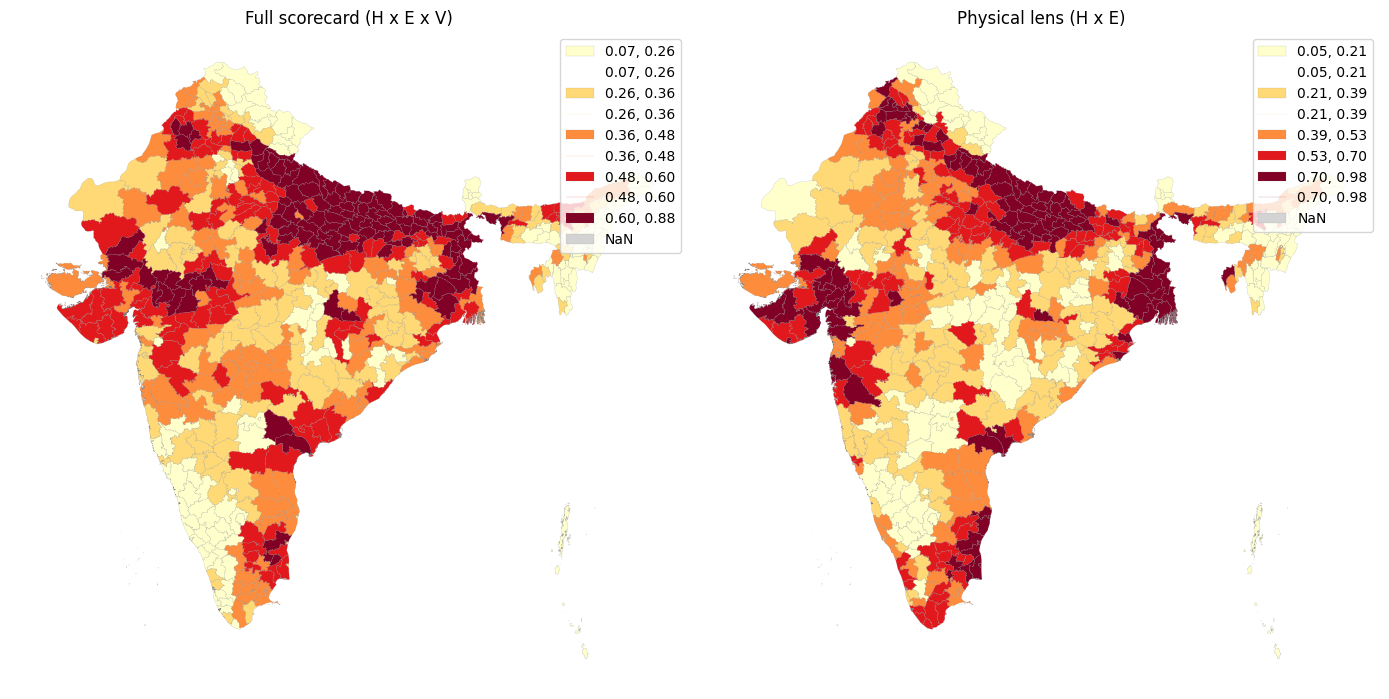

In [ ]:
import os
import matplotlib.pyplot as plt

mp = dist_gdf[["ADM2_CODE", "geometry"]].merge(df[["ADM2_CODE", "risk", "risk_physical"]], on="ADM2_CODE")
fig, ax = plt.subplots(1, 2, figsize=(14, 7))
for a, col, t in zip(ax, ["risk", "risk_physical"], ["Full scorecard (H x E x V)", "Physical lens (H x E)"]):
    mp.plot(column=col, cmap="YlOrRd", scheme="quantiles", k=5, legend=True, linewidth=0.1, edgecolor="grey",
            missing_kwds={"color": "lightgrey"}, ax=a)
    a.set_title(t); a.axis("off")
plt.tight_layout()

output_dir = f"{save_path}/outputs"
os.makedirs(output_dir, exist_ok=True)
plt.savefig(f"{output_dir}/risk_maps.png", dpi=200)